# Telecom Customer Churn Prediction – Model Building

## 1. Introduction

In this notebook, we will build machine learning models to predict customer churn.

We will use the preprocessed training and testing datasets generated in the previous notebook.

### Objectives

- Load the preprocessed datasets.
- Understand the machine learning algorithms.
- Train multiple classification models.
- Compare their performance.
- Identify a suitable model for predicting customer churn.

### Machine Learning Algorithms

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

## 2. Loading Preprocessed Datasets

We have already completed data preprocessing in the previous notebook.

In this step, we will load the saved training and testing datasets.

The feature matrices are stored in SciPy's sparse matrix format, while the target labels are stored as CSV files.

These datasets will be used to train and evaluate our machine learning models.

In [1]:
import pandas as pd
import numpy as np

from scipy.sparse import load_npz

# Load processed features
X_train = load_npz("../data/processed/X_train_processed.npz")
X_test = load_npz("../data/processed/X_test_processed.npz")

# Load target labels
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 46)
Testing features: (1409, 46)
Training target: (5634,)
Testing target: (1409,)


## 3. Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict categorical outcomes.

In this project, it will predict whether a telecom customer is likely to churn (Yes) or stay (No).

The algorithm estimates the probability of a customer churning based on their characteristics.

We will use Logistic Regression as our baseline model and compare its performance with other classification algorithms.

## 4. Training the Logistic Regression Model

We will import Logistic Regression from Scikit-learn and train it using our preprocessed training dataset.

The model will learn patterns and relationships between customer characteristics and churn behaviour.

We will use the trained model later to predict churn for customers in the testing dataset.

In [3]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [4]:
from sklearn.linear_model import LogisticRegression

In [5]:
logistic_model = LogisticRegression(max_iter=1000)

In [6]:
logistic_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## 5. Making Predictions Using Logistic Regression

After training the Logistic Regression model, we will use it to predict customer churn on the testing dataset.

The testing dataset contains customer records that the model has not seen during training.

This helps us understand how well the model can predict churn for unseen customers.

In [7]:
y_pred_logistic = logistic_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred_logistic[:10])

First 10 actual values:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted values:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


## 6. Evaluating Logistic Regression Accuracy

After making predictions, we need to evaluate how accurately the model predicts customer churn.

We will use Accuracy Score to calculate the proportion of correct predictions out of all predictions made on the testing dataset.

Accuracy helps us understand the overall correctness of the model.

In [8]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Logistic Regression Accuracy: 0.8055358410220014
Accuracy Percentage: 80.55358410220013


## 7. Classification Report – Logistic Regression

Accuracy provides an overall measure of prediction correctness, but it does not explain how well the model identifies each class.

We will use a classification report to evaluate:

- Precision
- Recall
- F1-score
- Support

These metrics help us understand how effectively the model identifies customers who churn and customers who stay.

In [9]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Logistic Regression – Performance Analysis

The Logistic Regression model achieved an accuracy of 80.55% on the testing dataset.

Key observations:

- The model achieved 85% precision and 89% recall for customers who stayed.
- For customers who churned, it achieved 66% precision and 56% recall.
- The F1-score for the churn class was 0.60.
- The model performs better at identifying customers who stay than customers who churn.

**Business Insight:**

The model currently misses approximately 44% of actual churn customers. Improving churn recall should be an important objective in the next stages of model development.

## 8. Confusion Matrix – Logistic Regression

A confusion matrix is used to evaluate the performance of a classification model.

It compares actual customer churn labels with predicted churn labels.

It helps identify:
- True Positives (TP)
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)

This is particularly useful in churn prediction because false negatives represent customers who actually churned but were incorrectly predicted to stay.

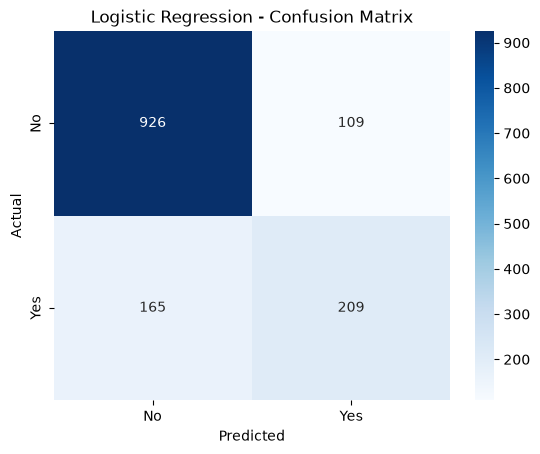

In [10]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_logistic)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Confusion Matrix – Interpretation

The Logistic Regression model produced the following results:

- True Negative: 926
- False Positive: 109
- False Negative: 165
- True Positive: 209

**Business Insights:**

1. The model correctly identified 926 customers who stayed.
2. It incorrectly flagged 109 customers as potential churners.
3. It failed to identify 165 customers who actually churned.
4. It successfully identified 209 customers who churned.

The number of false negatives indicates that the model misses several actual churn customers.

Therefore, improving the model's ability to identify churn customers will be an important focus in subsequent model development.

## 9. ROC-AUC Evaluation – Logistic Regression

ROC-AUC is an evaluation metric used to measure how effectively a classification model distinguishes between different classes.

Unlike accuracy, which evaluates predictions at a particular classification threshold, ROC-AUC evaluates the model's ability to distinguish between classes across different thresholds.

In this project, it measures how well Logistic Regression separates customers who churn from customers who stay.

In [12]:
from sklearn.metrics import roc_auc_score

# Get churn probabilities
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression ROC-AUC:", roc_auc)

Logistic Regression ROC-AUC: 0.8420341522643313


### ROC-AUC – Logistic Regression Findings

The Logistic Regression model achieved a ROC-AUC score of 0.8420 (84.20%).

This indicates that the model has good ability to distinguish between customers who churn and customers who stay.

**Key Observation:**

Although the model achieved good overall classification performance, its recall for the churn class is only 56%.

Therefore, improving churn detection while maintaining a reasonable precision will be an important objective in further model development.

## 10. Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm used for classification and regression tasks.

It learns decision rules from training data and represents them in a tree-like structure consisting of decision nodes and leaf nodes.

In this project, the Decision Tree Classifier will learn patterns from customer information to predict whether a customer is likely to churn.

We will compare its performance with Logistic Regression to understand which algorithm performs better for our churn prediction problem.

In [13]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


## 11. Making Predictions Using Decision Tree

After training the Decision Tree Classifier, we will use it to predict customer churn on the testing dataset.

The model will analyse the customer features and classify each customer as either likely to churn or likely to stay.

These predictions will be compared with the actual churn labels to evaluate the model's performance.

In [14]:
y_pred_tree = decision_tree_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred_tree[:10])

First 10 actual values:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted values:
['No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'Yes']


## 12. Evaluating Decision Tree Accuracy

We will calculate the accuracy of the Decision Tree Classifier using the testing dataset.

Accuracy measures the percentage of customer records for which the model correctly predicts the churn outcome.

In [15]:
from sklearn.metrics import accuracy_score

accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)
print("Accuracy Percentage:", accuracy_tree * 100)

Decision Tree Accuracy: 0.7224982256919801
Accuracy Percentage: 72.249822569198


## 13. Classification Report – Decision Tree

We will evaluate the Decision Tree Classifier using precision, recall, F1-score and support.

These metrics help us understand how effectively the model identifies customers who churn and customers who stay.

We will pay particular attention to recall for the churn class because identifying potential churners is important for customer retention.

In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

          No       0.81      0.81      0.81      1035
         Yes       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409



### Decision Tree – Performance Analysis

The Decision Tree Classifier achieved an accuracy of 72.25% on the testing dataset.

Key observations:

- Precision for the churn class: 48%.
- Recall for the churn class: 49%.
- F1-score for the churn class: 48%.
- The model performs better at identifying customers who stay than customers who churn.

**Business Insight:**

The model misses approximately 51% of actual churn customers. Its performance is currently lower than Logistic Regression across the evaluated metrics.

Further improvements, including controlling tree complexity and hyperparameter tuning, may help improve its performance.

## 14. Confusion Matrix – Decision Tree

A confusion matrix compares the actual churn labels with the predictions made by the Decision Tree Classifier.

It helps us understand correct predictions and identify the types of mistakes made by the model.

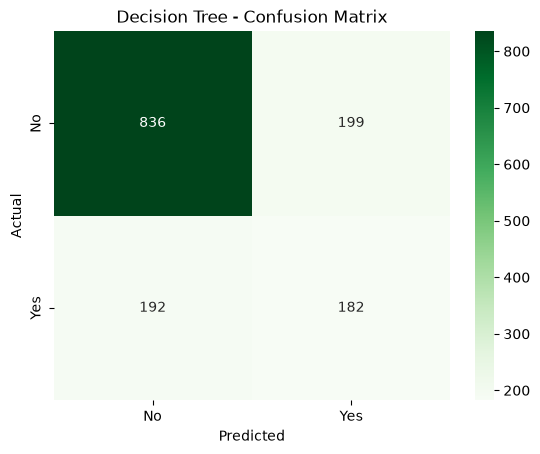

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_tree = confusion_matrix(y_test, y_pred_tree)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

### Confusion Matrix – Decision Tree Interpretation

The Decision Tree Classifier produced the following results:

- True Negative: 836
- False Positive: 199
- False Negative: 192
- True Positive: 182

**Business Insights:**

1. The model correctly identified 836 customers who stayed.
2. It incorrectly flagged 199 customers as potential churners.
3. It failed to identify 192 customers who actually churned.
4. It successfully identified 182 customers who churned.

The model has a relatively high number of false negatives, indicating that it misses several actual churn customers.

Compared with Logistic Regression, the Decision Tree currently has lower churn detection performance.

## 15. ROC-AUC Evaluation – Decision Tree

We will calculate the ROC-AUC score to measure the ability of the Decision Tree Classifier to distinguish between customers who churn and customers who stay.

We will use predicted probabilities rather than predicted class labels.

In [18]:
from sklearn.metrics import roc_auc_score

# Get churn probabilities
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_auc_tree = roc_auc_score(y_test, y_prob_tree)

print("Decision Tree ROC-AUC:", roc_auc_tree)

Decision Tree ROC-AUC: 0.6469322379808313


### ROC-AUC – Decision Tree Findings

The Decision Tree Classifier achieved a ROC-AUC score of 0.6469 (64.69%).

This indicates relatively weak discrimination between customers who churn and customers who stay.

Compared with Logistic Regression, the Decision Tree achieved lower performance across the evaluated metrics.

**Observation:**

The default Decision Tree model may benefit from hyperparameter tuning and complexity control to improve its generalization performance.

## 16. Random Forest Classifier

Random Forest is a supervised machine learning algorithm used for classification and regression tasks.

It combines multiple Decision Trees and makes predictions using majority voting.

Each tree learns patterns from different samples and feature subsets of the training data.

In this project, Random Forest will learn customer behaviour patterns and predict whether customers are likely to churn.

We will compare its performance with Logistic Regression and Decision Tree Classifier to identify the most suitable model.

In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 17. Making Predictions Using Random Forest

After training the Random Forest Classifier, we will use it to predict customer churn on the testing dataset.

The model combines predictions from multiple decision trees to classify customers as either likely to churn or likely to stay.

We will compare these predictions with the actual churn labels to evaluate the model's performance.

In [20]:
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

First 10 actual values:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted values:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


## 18. Evaluating Random Forest Accuracy

We will calculate the accuracy of the Random Forest Classifier using the testing dataset.

Accuracy measures the proportion of customer records for which the model correctly predicts the churn outcome.

In [21]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Accuracy Percentage:", accuracy_rf * 100)

Random Forest Accuracy: 0.7885024840312278
Accuracy Percentage: 78.85024840312278


## 19. Classification Report – Random Forest

We will evaluate the Random Forest Classifier using precision, recall, F1-score and support.

These metrics help us understand how effectively the model identifies customers who churn and customers who stay.

Special attention will be given to the recall and F1-score of the churn class because identifying potential churn customers is important for customer retention.

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### Random Forest – Performance Analysis

The Random Forest Classifier achieved an accuracy of 78.85% on the testing dataset.

Key observations:

- Precision for the churn class: 63%.
- Recall for the churn class: 49%.
- F1-score for the churn class: 55%.
- The model performs better at identifying customers who stay than customers who churn.

**Business Insight:**

The model misses approximately 51% of actual churn customers. Although Random Forest performs better than the individual Decision Tree in several metrics, its churn recall is lower than Logistic Regression.

Further model improvements are required to increase churn detection.

## 20. Confusion Matrix – Random Forest

A confusion matrix compares actual customer churn labels with the predictions made by the Random Forest Classifier.

It helps us identify correct predictions, false positives and false negatives.

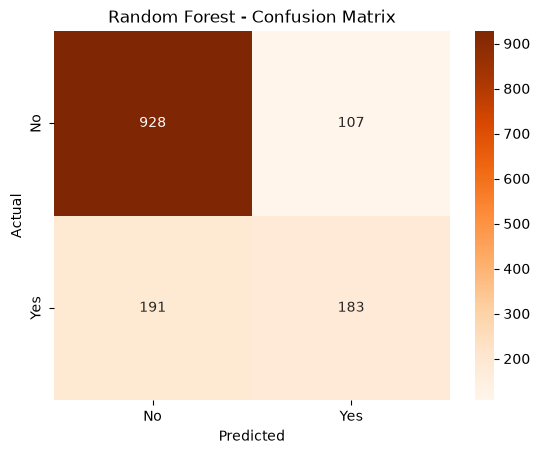

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

### Confusion Matrix – Random Forest Interpretation

The Random Forest Classifier produced the following results:

- True Negative: 928
- False Positive: 107
- False Negative: 191
- True Positive: 183

**Business Insights:**

1. The model correctly identified 928 customers who stayed.
2. It incorrectly flagged 107 customers as potential churners.
3. It failed to identify 191 customers who actually churned.
4. It successfully identified 183 customers who churned.

The model has fewer false positives than the Decision Tree, but it still misses a significant number of actual churn customers.

Improving churn detection remains an important objective.

## 21. ROC-AUC Evaluation – Random Forest

We will calculate the ROC-AUC score to evaluate the ability of the Random Forest Classifier to distinguish between customers who churn and customers who stay.

We will use predicted probabilities rather than predicted class labels.

In [24]:
from sklearn.metrics import roc_auc_score

# Get churn probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.820127102224289


### ROC-AUC – Random Forest Findings

The Random Forest Classifier achieved a ROC-AUC score of 0.8201 (82.01%).

This indicates that the model has good ability to distinguish between customers who churn and customers who stay.

**Observations:**

- Random Forest performs better than the individual Decision Tree.
- Its ROC-AUC score is slightly lower than Logistic Regression.
- The model still requires improvement in identifying actual churn customers.

Further optimization may help improve churn prediction performance.

In [25]:
import joblib

joblib.dump(logistic_model, "../models/logistic_regression.pkl")
joblib.dump(decision_tree_model, "../models/decision_tree.pkl")
joblib.dump(random_forest_model, "../models/random_forest.pkl")

print("All trained models saved successfully!")

All trained models saved successfully!
